# Q-learning

An agent starts at the bottom left of a six-by-six grid. It can move in four directions and learns from rewards. The goal pays +1, a pit pays −1, and other moves cost 0.04. A move into a wall leaves the agent where it is.

## Train with exploration

With probability 0.2, choose a random action. Otherwise pick one of the best-scoring actions, breaking ties at random. Update only the score for this cell and move. Stop an episode at the goal, a pit, or 72 steps. The final number measures how many moves the most recent successful training episodes averaged beyond the five-step shortest path.

In [1]:
import numpy as np
from sklearn.metrics import mean_absolute_error

grid = ["......", ".##.X.", "...#..", ".X.#..", "..#...", "S....G"]
moves = [(-1, 0), (0, 1), (1, 0), (0, -1)]
rng = np.random.default_rng(2026)
q = np.zeros((6, 6, 4))
steps, goal_steps = [], []

for episode in range(400):
    row, col = 5, 0
    for count in range(1, 73):
        values = q[row, col]
        best = np.flatnonzero(values == values.max())
        action = rng.integers(4) if rng.random() < .2 else rng.choice(best)
        dr, dc = moves[action]
        nr, nc = row + dr, col + dc
        if not (0 <= nr < 6 and 0 <= nc < 6) or grid[nr][nc] == "#":
            nr, nc = row, col
        tile = grid[nr][nc]
        reward = {"G": 1, "X": -1}.get(tile, -.04)
        terminal = tile in "GX"
        future = 0 if terminal else q[nr, nc].max()
        q[row, col, action] += .5 * (reward + .95 * future - values[action])
        row, col = nr, nc
        if terminal:
            break
    steps.append(count)
    if tile == "G":
        goal_steps.append(count)

recent = goal_steps[-30:]
print(f"Last {len(recent)} episodes that reached the goal: {np.mean(recent):.1f} steps on average (the shortest path is 5).")
print(f"Average extra steps compared with the shortest path: {mean_absolute_error([5] * len(recent), recent):.2f}")

Last 30 episodes that reached the goal: 6.6 steps on average (the shortest path is 5).
Average extra steps compared with the shortest path: 1.63


## See it

The line shows a moving average over the most recent 20 training episodes. Falling into a pit can also make an episode short, so inspect the greedy policy too. The arrows on the right show the best-scoring move after training. Follow the arrows from S to G.

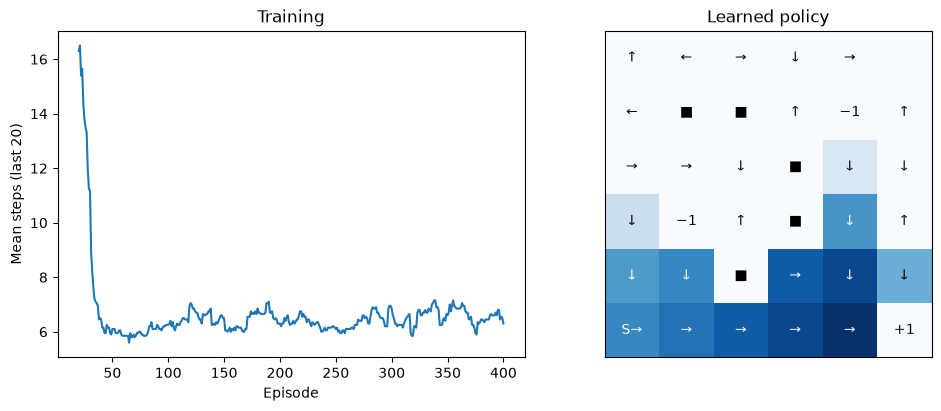

In [2]:
import matplotlib.pyplot as plt

averaged = np.convolve(steps, np.ones(20) / 20, mode="valid")
fig, (trend, policy) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
trend.plot(np.arange(20, len(steps) + 1), averaged)
trend.set(xlabel="Episode", ylabel="Mean steps (last 20)", title="Training")
policy.imshow(q.max(axis=-1), vmin=0, vmax=1, cmap="Blues")
for row, tiles in enumerate(grid):
    for col, tile in enumerate(tiles):
        value = q[row, col]
        arrow = "↑→↓←"[value.argmax()] if np.any(value) else ""
        label = {"#": "■", "S": f"S{arrow}", "G": "+1", "X": "−1"}.get(tile, arrow)
        policy.text(col, row, label, ha="center", va="center",
                    color="white" if value.max() > 0.58 else "black")
policy.set(title="Learned policy", xticks=[], yticks=[])
plt.show()